In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df=pd.read_csv('/content/drive/MyDrive/titanic_toy.csv')

In [5]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


In [7]:
df.isnull().mean()

,0
Age,0.198653
Fare,0.050505
Family,0.000000
Survived,0.000000


In [9]:
X=df[['Age','Fare','Family']]
Y=df[['Survived']]

In [10]:
# we should impute on only age and fare columns
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=2)

In [11]:
X_train.shape,X_test.shape

((712, 3), (179, 3))

In [12]:
X_train.isnull().mean()

,0
Age,0.207865
Fare,0.050562
Family,0.000000


In [15]:
mean_age=X_train['Age'].mean()
median_age=X_train['Age'].median()

mean_fare=X_train['Fare'].mean()
median_fare=X_train['Fare'].median()

In [16]:
mean_age,median_age,mean_fare,median_fare

(np.float64(29.78590425531915), 28.75, np.float64(32.61759689349112), 14.4583)

In [17]:
X_train['Age_mean']=X_train['Age'].fillna(mean_age)
X_train['Age_median']=X_train['Age'].fillna(median_age)
X_train['Fare_mean']=X_train['Fare'].fillna(mean_fare)
X_train['Fare_median']=X_train['Fare'].fillna(median_fare)


In [20]:
X_train.sample(5)

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
547,NaN,13.8625,0,29.785904,28.75,13.8625,13.8625
53,29.0,26.0000,1,29.000000,29.00,26.0000,26.0000
41,27.0,21.0000,1,27.000000,27.00,21.0000,21.0000
125,12.0,11.2417,1,12.000000,12.00,11.2417,11.2417
132,47.0,14.5000,1,47.000000,47.00,14.5000,14.5000


In [22]:
print('Original Age variable variance ',X_train['Age'].var())
print('Age variance after mean imputation ',X_train['Age_mean'].var())
print('Age variance after median imputation ',X_train['Age_median'].var())
print()
print('Original Fare variable variance ',X_train['Fare'].var())
print('Fare variance after mean imputation ',X_train['Fare_mean'].var())
print('Fare variance after median imputation ',X_train['Fare_median'].var())

Original Age variable variance  204.3495133904614
Age variance after mean imputation  161.81262452718673
Age variance after median imputation  161.9895663346054

Original Fare variable variance  2448.197913706318
Fare variance after mean imputation  2324.2385256705547
Fare variance after median imputation  2340.0910219753637


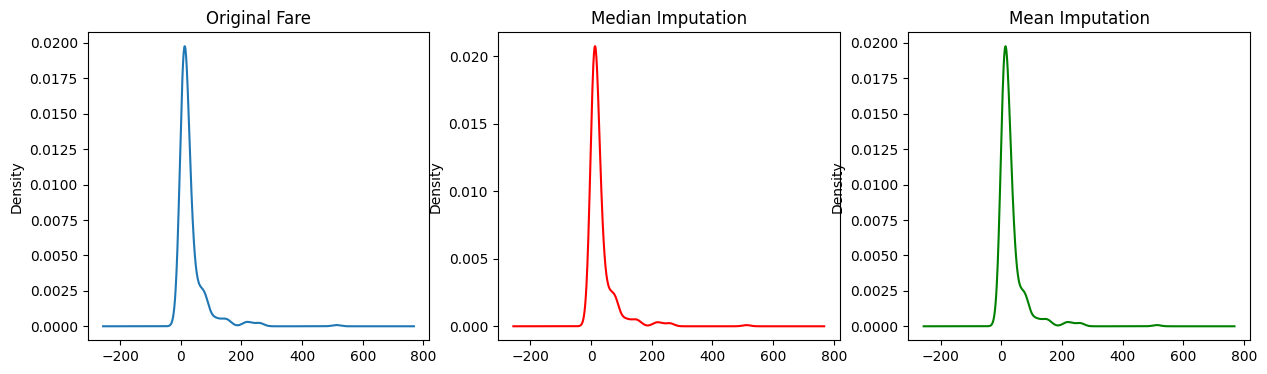

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# original variable distribution
X_train['Fare'].plot(kind='kde',ax=ax[0],title="Original Fare")

# variable imputed with the median
X_train['Fare_median'].plot(kind='kde',ax=ax[1],color='red',title='Median Imputation')

X_train['Fare_mean'].plot(kind='kde',ax=ax[2],color='green',title='Mean Imputation')

plt.show()


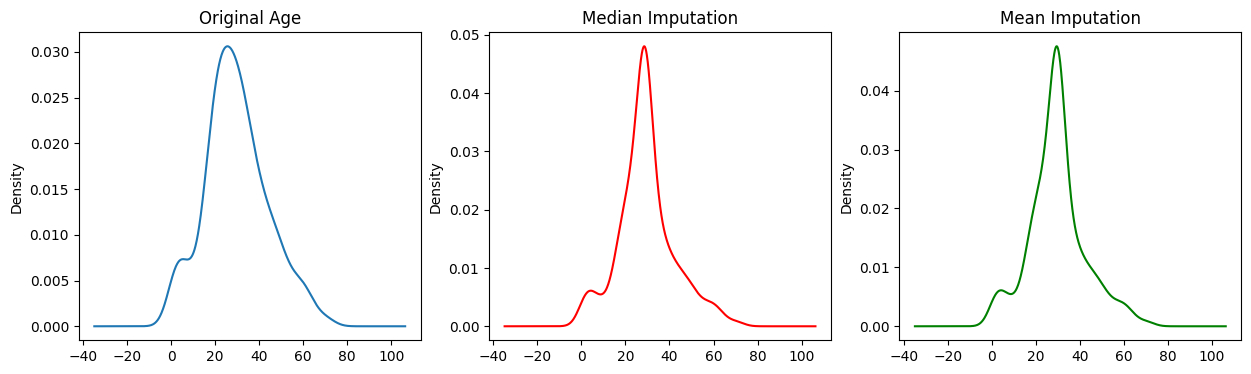

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# original variable distribution
X_train['Age'].plot(kind='kde',ax=ax[0],title="Original Age")

# variable imputed with the median
X_train['Age_median'].plot(kind='kde',ax=ax[1],color='red',title='Median Imputation')

X_train['Age_mean'].plot(kind='kde',ax=ax[2],color='green',title='Mean Imputation')

plt.show()

To find changes in covariance

In [27]:
X_train.cov()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,204.349513,70.719262,-6.498901,204.349513,204.349513,66.665205,64.858859
Fare,70.719262,2448.197914,17.258917,55.603719,57.957599,2448.197914,2448.197914
Family,-6.498901,17.258917,2.735252,-5.146106,-5.112563,16.385048,16.476305
Age_mean,204.349513,55.603719,-5.146106,161.812625,161.812625,52.788341,51.358000
Age_median,204.349513,57.957599,-5.112563,161.812625,161.989566,55.023037,53.553455
Fare_mean,66.665205,2448.197914,16.385048,52.788341,55.023037,2324.238526,2324.238526
Fare_median,64.858859,2448.197914,16.476305,51.358000,53.553455,2324.238526,2340.091022


To find changes in correlation

Correlation stays from

In [28]:
X_train.corr()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,1.000000,0.092644,-0.299113,1.000000,1.000000,0.090156,0.087356
Fare,0.092644,1.000000,0.208268,0.088069,0.091757,1.000000,1.000000
Family,-0.299113,0.208268,1.000000,-0.244610,-0.242883,0.205499,0.205942
Age_mean,1.000000,0.088069,-0.244610,1.000000,0.999454,0.086078,0.083461
Age_median,1.000000,0.091757,-0.242883,0.999454,1.000000,0.089673,0.086982
Fare_mean,0.090156,1.000000,0.205499,0.086078,0.089673,1.000000,0.996607
Fare_median,0.087356,1.000000,0.205942,0.083461,0.086982,0.996607,1.000000


To detect Outliers use box plots

Outliers have increased after applying mean median imputation

<Axes: >

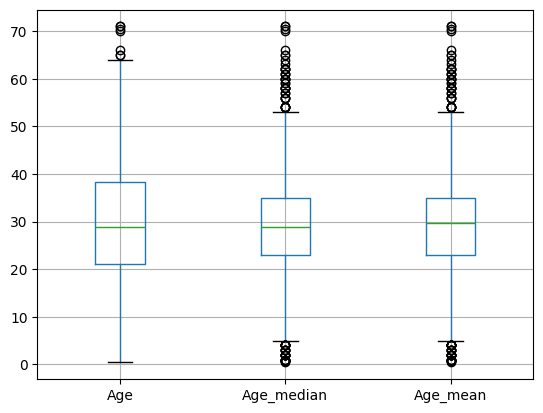

In [29]:
X_train[['Age','Age_median','Age_mean']].boxplot()

Outliers are on both side of BOX PLOT

<Axes: >

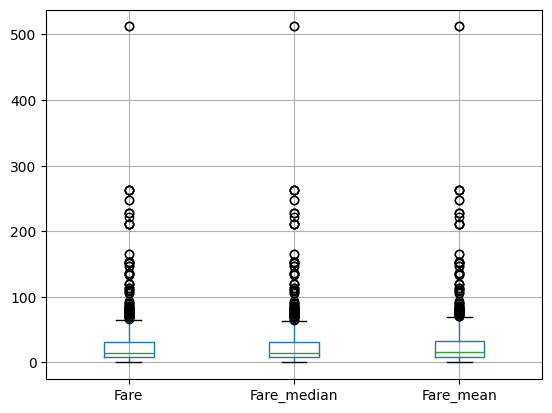

In [30]:
X_train[['Fare','Fare_median','Fare_mean']].boxplot()

In [31]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=2)

In [32]:
imputer1=SimpleImputer(strategy='median')
imputer2=SimpleImputer(strategy='mean')

Applying median on age column

Applying mean on fare column

In [33]:
trf=ColumnTransformer([
    ('imputer1',imputer1,['Age']),
    ('imputer2',imputer2,['Fare']),
],remainder='passthrough')

In [34]:
trf.fit(X_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('imputer1', SimpleImputer(strategy='median'),
                                 ['Age']),
                                ('imputer2', SimpleImputer(), ['Fare'])])

In [37]:
# median value of age
trf.named_transformers_['imputer1'].statistics_

array([28.75])

In [38]:
# mean value of fare
trf.named_transformers_['imputer2'].statistics_

array([32.61759689])

Applying this transform on X_train and X_test

In [39]:
X_train=trf.transform(X_train)
X_test=trf.transform(X_test)

In [40]:
X_train

array([[ 40.    ,  27.7208,   0.    ],
       [  4.    ,  16.7   ,   2.    ],
       [ 47.    ,   9.    ,   0.    ],
       ...,
       [ 71.    ,  49.5042,   0.    ],
       [ 28.75  , 221.7792,   0.    ],
       [ 28.75  ,  25.925 ,   0.    ]])

In [41]:
X_test

array([[ 42.        ,  26.2875    ,   0.        ],
       [ 21.        ,   8.05      ,   0.        ],
       [ 24.        ,  65.        ,   3.        ],
       [ 28.        ,  56.4958    ,   0.        ],
       [ 17.        ,   7.925     ,   6.        ],
       [ 30.        ,   7.8958    ,   0.        ],
       [ 80.        ,  30.        ,   0.        ],
       [ 25.        ,   7.25      ,   0.        ],
       [ 50.        , 133.65      ,   2.        ],
       [ 25.        ,  26.        ,   1.        ],
       [ 35.        ,  26.        ,   0.        ],
       [ 35.        ,  90.        ,   1.        ],
       [ 55.        ,  16.        ,   0.        ],
       [ 28.75      ,  56.4958    ,   0.        ],
       [ 28.75      ,  56.4958    ,   0.        ],
       [ 19.        ,   7.8542    ,   1.        ],
       [ 28.75      ,  15.2458    ,   2.        ],
       [ 49.        ,   0.        ,   0.        ],
       [ 18.        ,  32.61759689,   1.        ],
       [ 65.        ,   7.75   